Inventaire des nouvelles données

Ce notebook examine les jeux de données placés dans `data/sources/`, sans rien modifier :

1. la structure des dossiers;
2. le nombre d'images par dossier;
3. des exemples d'images;
4. la taille et le format des images.

Cliquez sur **Run All** en haut du notebook.

In [1]:
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SOURCES = RACINE / "data" / "sources"
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", None)

def images_de(dossier):
    return sorted(p for p in dossier.iterdir() if p.is_file() and p.suffix.lower() in EXTENSIONS)

print("Dossier des sources :", SOURCES)
print("Existe :", SOURCES.is_dir())

Dossier des sources : c:\Users\Jonathan\diagnostic-defauts\data\sources
Existe : True


## 1. Structure des dossiers

In [2]:
def afficher_arbre(dossier, niveau=0, niveau_max=4):
    if niveau > niveau_max:
        return
    sous_dossiers = sorted(p for p in dossier.iterdir() if p.is_dir())
    n = len(images_de(dossier))
    info = f"   ({n} images)" if n else ""
    print("    " * niveau + f"{dossier.name}/" + info)
    for s in sous_dossiers:
        afficher_arbre(s, niveau + 1, niveau_max)

afficher_arbre(SOURCES)

sources/
    casting/
        casting_512x512/
            casting_512x512/
                def_front/   (781 images)
                ok_front/   (519 images)
        casting_data/
            casting_data/
                test/
                train/
        NEU-DET/
            train/
                annotations/
                images/
            validation/
                annotations/
                images/
    pneus/
        Digital images of defective and good condition tyres/
            defective/   (1028 images)
            good/   (828 images)


## 2. Nombre d'images par dossier

In [3]:
lignes = []
for dossier in sorted(p for p in SOURCES.rglob("*") if p.is_dir()):
    n = len(images_de(dossier))
    if n:
        relatif = dossier.relative_to(SOURCES)
        lignes.append({"Jeu": relatif.parts[0], "Dossier": str(relatif.as_posix()), "Images": n})

inventaire = pd.DataFrame(lignes)
display(inventaire)
print("Total :", inventaire["Images"].sum(), "images")

,Jeu,Dossier,Images
0,casting,casting/casting_512x512/casting_512x512/def_front,781
1,casting,casting/casting_512x512/casting_512x512/ok_front,519
2,casting,casting/casting_data/casting_data/test/def_front,453
3,casting,casting/casting_data/casting_data/test/ok_front,262
4,casting,casting/casting_data/casting_data/train/def_front,3758
5,casting,casting/casting_data/casting_data/train/ok_front,2875
6,casting,casting/NEU-DET/train/images/crazing,240
7,casting,casting/NEU-DET/train/images/inclusion,240
8,casting,casting/NEU-DET/train/images/patches,240
9,casting,casting/NEU-DET/train/images/pitted_surface,240


Total : 12304 images


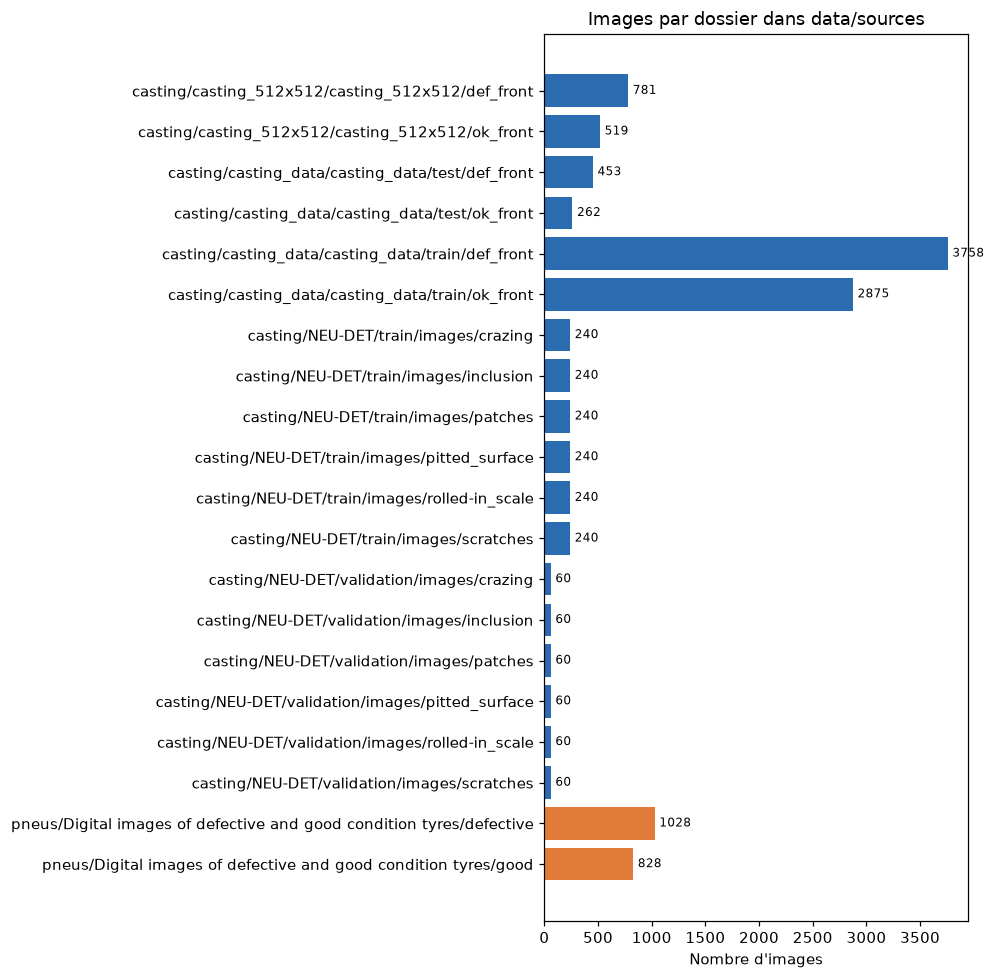

In [4]:
fig, ax = plt.subplots(figsize=(9, max(3, 0.45 * len(inventaire))))
couleurs = {jeu: c for jeu, c in zip(inventaire["Jeu"].unique(), ["#2b6cb0", "#e07b39", "#2f9e44", "#9c36b5", "#c92a2a"])}
ax.barh(inventaire["Dossier"], inventaire["Images"], color=[couleurs[j] for j in inventaire["Jeu"]])
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Nombre d'images")
ax.set_title("Images par dossier dans data/sources")
plt.tight_layout()
plt.show()

## 3. Exemples d'images

Quatre images choisies au hasard dans chaque dossier.

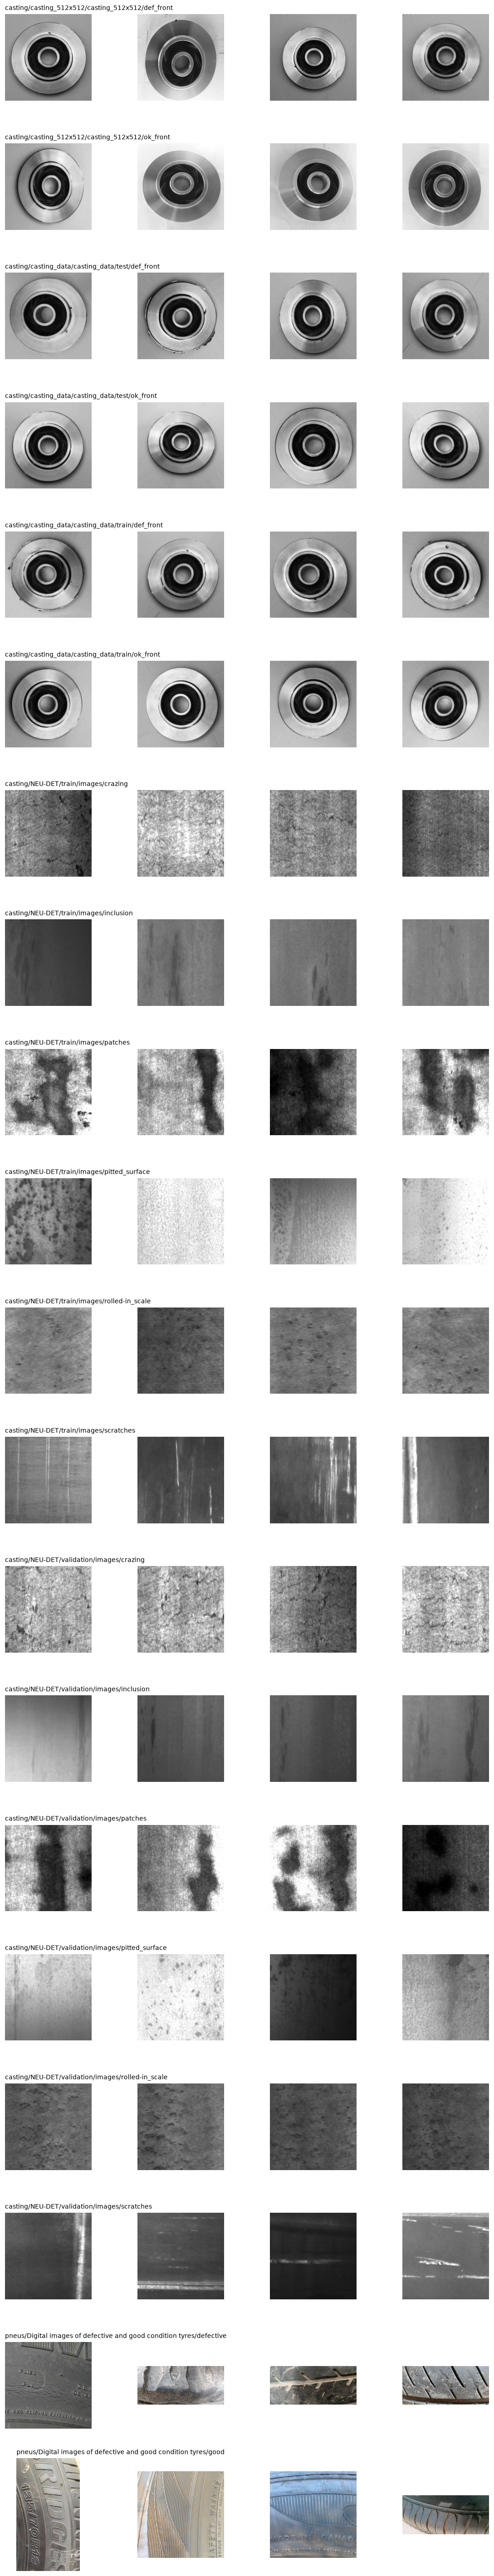

In [5]:
random.seed(0)
dossiers = [SOURCES / d for d in inventaire["Dossier"]]
fig, axes = plt.subplots(len(dossiers), 4, figsize=(10, 2.6 * len(dossiers)), squeeze=False)
for i, dossier in enumerate(dossiers):
    exemples = random.sample(images_de(dossier), min(4, len(images_de(dossier))))
    for j in range(4):
        ax = axes[i, j]
        ax.axis("off")
        if j < len(exemples):
            ax.imshow(Image.open(exemples[j]).convert("RGB"))
    axes[i, 0].set_title(str(dossier.relative_to(SOURCES).as_posix()), loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## 4. Taille et format des images

Calculés sur un échantillon de 20 images par dossier.

In [6]:
lignes = []
for dossier in dossiers:
    for chemin in random.sample(images_de(dossier), min(20, len(images_de(dossier)))):
        with Image.open(chemin) as im:
            lignes.append({"Dossier": str(dossier.relative_to(SOURCES).as_posix()),
                           "Largeur": im.width, "Hauteur": im.height, "Mode": im.mode,
                           "Format": chemin.suffix.lower()})
tailles = pd.DataFrame(lignes)
resume = tailles.groupby("Dossier").agg(
    Largeur_min=("Largeur", "min"), Largeur_max=("Largeur", "max"),
    Hauteur_min=("Hauteur", "min"), Hauteur_max=("Hauteur", "max"),
    Modes=("Mode", lambda m: ", ".join(sorted(set(m)))),
    Formats=("Format", lambda f: ", ".join(sorted(set(f)))),
)
resume

,Largeur_min,Largeur_max,Hauteur_min,Hauteur_max,Modes,Formats
Dossier,,,,,,
casting/NEU-DET/train/images/crazing,200,200,200,200,RGB,.jpg
casting/NEU-DET/train/images/inclusion,200,200,200,200,RGB,.jpg
casting/NEU-DET/train/images/patches,200,200,200,200,RGB,.jpg
casting/NEU-DET/train/images/pitted_surface,200,200,200,200,RGB,.jpg
casting/NEU-DET/train/images/rolled-in_scale,200,200,200,200,RGB,.jpg
casting/NEU-DET/train/images/scratches,200,200,200,200,RGB,.jpg
casting/NEU-DET/validation/images/crazing,200,200,200,200,RGB,.jpg
casting/NEU-DET/validation/images/inclusion,200,200,200,200,RGB,.jpg
casting/NEU-DET/validation/images/patches,200,200,200,200,RGB,.jpg
